# 04 · Innovation clustering

BERTopic (UMAP + HDBSCAN) on the MiniLM embeddings, across all documents (`G-*` clusters) and
within each domain (`AI-*`, `HC-*`, `RB-*`, `CS-*`, `RE-*` sub-areas). Produced by
`python -m src.pipeline.cluster`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from umap import UMAP

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
ev = json.loads(Path("reports/clustering_eval.json").read_text())
clusters = pd.read_parquet("data/outputs/clusters.parquet")
assign = pd.read_parquet("data/outputs/doc_clusters.parquet")
docs = pd.read_parquet("data/processed/documents.parquet").merge(assign, on="doc_id")
vec = np.load("data/processed/embeddings_minilm.npy")

## Metrics
- **Silhouette** (cosine, original 384-d space, outliers excluded) is low but positive: research
  topics overlap and form a continuum rather than well-separated blobs.
- **NMI** against the 5 domain labels measures how much the clusters agree with the domains.
  **ARI** is much lower because it penalises splitting one domain into many sub-areas, which is
  exactly what we want from 100 clusters.

In [2]:
g = ev["global"]
pd.DataFrame(
    [{"scope": "global", **{k: g[k] for k in ("clusters", "outlier_share", "silhouette_cosine_excl_outliers")},
      "nmi": g["nmi_vs_domain_excl_outliers"], "ari": g["ari_vs_domain_excl_outliers"]}]
    + [{"scope": d, **v} for d, v in ev["domain"].items()]
)

,scope,clusters,outlier_share,silhouette_cosine_excl_outliers,nmi,ari
0,global,94,0.2679,0.0965,0.4814,0.1327
1,Artificial Intelligence,36,0.2130,0.0960,NaN,NaN
2,Healthcare,33,0.2587,0.1170,NaN,NaN
3,Robotics,33,0.2458,0.0813,NaN,NaN
4,Cybersecurity,39,0.2690,0.0948,NaN,NaN
5,Renewable Energy,20,0.0622,0.0803,NaN,NaN


## Global clusters in 2-D
A 2-D UMAP of the embeddings coloured by domain, with the ten largest global clusters labelled.

C:\Users\parka\Documents\INT395 Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


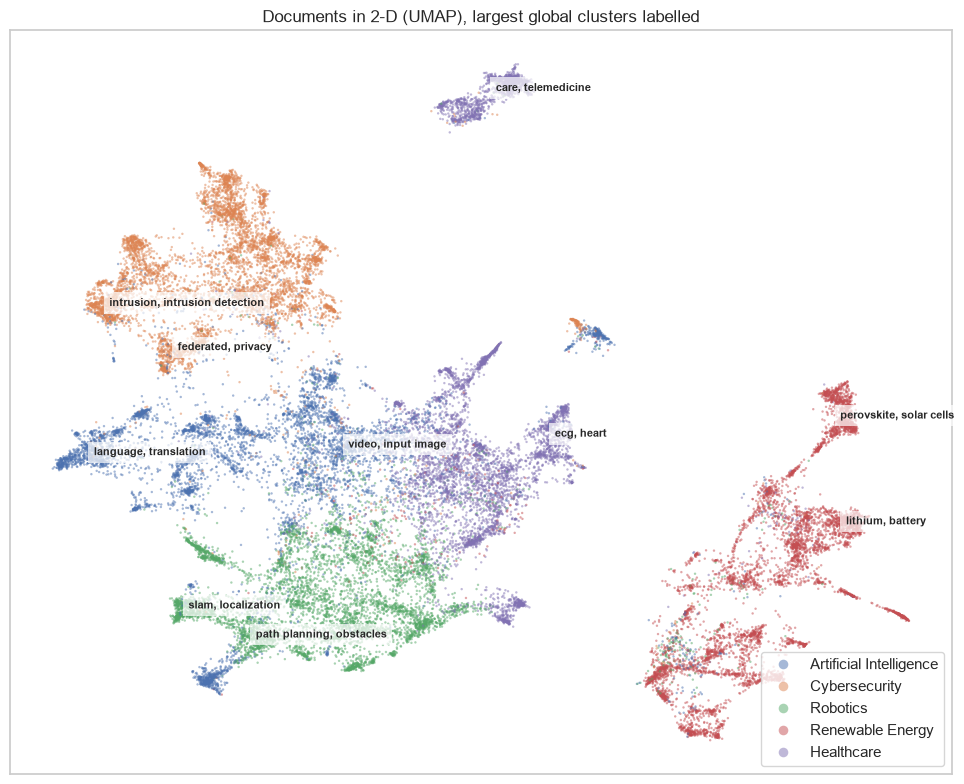

In [3]:
xy = UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(vec)
docs["x"], docs["y"] = xy[:, 0], xy[:, 1]
fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=docs, x="x", y="y", hue="domain", s=3, linewidth=0, alpha=0.5, ax=ax)
glob = clusters[clusters["scope"] == "global"].nlargest(10, "size")
for _, c in glob.iterrows():
    pts = docs.loc[docs["global_cluster"] == c["cluster_id"], ["x", "y"]].median()
    ax.text(pts["x"], pts["y"], ", ".join(list(c["keywords"])[:2]), fontsize=8, weight="bold",
            bbox=dict(facecolor="white", alpha=0.7, lw=0))
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
ax.legend(markerscale=4, loc="lower right"); ax.set_title("Documents in 2-D (UMAP), largest global clusters labelled")
plt.tight_layout(); plt.savefig(FIG / "clusters_umap.png", dpi=150); plt.show()

## Cross-domain clusters
Global clusters that mix domains show where technologies meet, such as AI methods applied to
medical images.

In [4]:
mix = docs.groupby("global_cluster")["domain"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).rename("top_domain_share")
glob_all = clusters[clusters["scope"] == "global"].set_index("cluster_id").join(mix)
glob_all["keywords"] = glob_all["keywords"].map(lambda k: ", ".join(list(k)[:6]))
glob_all.sort_values("top_domain_share")[["size", "top_domain_share", "keywords"]].head(10)

,size,top_domain_share,keywords
cluster_id,,,
G-68,249,0.502008,"distribution network, voltage, power distribut..."
G-31,300,0.526667,"autonomous vehicle, lane, vehicles, driver, tr..."
G-55,283,0.600707,"cancer, segmentation, tumor, medical image, ti..."
G-74,279,0.609319,"rehabilitation, limb, virtual reality, acceler..."
G-16,352,0.633523,"quantum, qubits, key distribution, photonic, g..."
G-79,126,0.746032,"audio, speech, sound, audio signal, acoustic, ..."
G-91,130,0.761538,"spinal, fractures, spine, fracture, segmentati..."
G-82,186,0.779570,"needle, tissue, tip, catheter, robotic, steerable"
G-20,491,0.782077,"eye, oct, beam, light source, optical coherenc..."


## Largest sub-areas per domain

In [5]:
sub = clusters[clusters["scope"] == "domain"].copy()
sub["keywords"] = sub["keywords"].map(lambda k: ", ".join(list(k)[:6]))
sub.sort_values("size", ascending=False).groupby("domain").head(5)[["domain", "cluster_id", "size", "keywords"]]

,domain,cluster_id,size,keywords
235,Renewable Energy,RE-0,2504,"electrode, electrolyte, lithium, substrate, an..."
130,Healthcare,HC-0,1239,"telemedicine, telehealth, healthcare, covid19,..."
236,Renewable Energy,RE-1,996,"solar cells, transport, quantum, defects, reco..."
94,Artificial Intelligence,AI-0,959,"text, translation, word, natural language, ent..."
163,Robotics,RB-0,722,"slam, lidar, odometry, localization mapping, i..."
196,Cybersecurity,CS-0,679,"federated, federated learning, privacypreservi..."
164,Robotics,RB-1,624,"inverse kinematics, calibration, synthesis, ma..."
197,Cybersecurity,CS-1,583,"intrusion, intrusion detection, ids, deep lear..."
95,Artificial Intelligence,AI-1,569,"swarm, optimization algorithm, particle swarm,..."
237,Renewable Energy,RE-2,419,"wind turbine, turbines, blade, wind turbines, ..."
